<a href="https://colab.research.google.com/github/sc8z35a-collab/RikiGaku-AHIRU/blob/main/colab/RikiGaku_AHIRU_V12_Verification_A100.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RikiGaku-AHIRU（AHIRU-μTJ42V）全12領域・一括物理検証システム（Google Colab Pro A100 GPU）

本ノートブックは、リポジトリの **[`index.html`](https://github.com/sc8z35a-collab/RikiGaku-AHIRU/blob/main/index.html)** から **58個の3D CADパーツ（Rev.2 100%水密ソリッド・ミリ単位座標）をビット完全抽出**し、現実で製造・飛行させた際に全物理現象・衝突・熱・構造・回路・制御・形式検証・製造性を突破できるかを **ワンクリック（`ランタイム` → `すべてのセルを実行` / `Ctrl+F9`）** で一括検証する航空宇宙グレード検証システムです。

### 実行環境・ツール総動員マトリクス（Colab Pro A100 GPU 実行 + 商用CAEネイティブ出力）

| 領域 | 検証内容 | Colab Pro (A100 GPU) ライブ実行エンジン | 商用ツール互換エクスポート（ZIP同梱） |
|---:|---|---|---|
| **01** | 3D CAD・静的/動的DMU衝突・6σ公差累積 | Node.js抽出 / `trimesh` / `python-fcl` / `CadQuery` / `OpenSCAD` / **A100 10万回モンテカルロGD&T** | STEP AP214, 58 STL, OpenSCAD (NX/CATIA/Creo/SolidWorks/CETOL 6σ) |
| **02** | CFD・ターボ機械・燃焼動力学・空力 | **`Cantera`** (詳細化学反応・PSR失火) / **A100 2D圧縮性Euler CFD** / **`XFOIL`** / `OpenFOAM` | OpenFOAM (`rhoSimpleFoam`), SU2 `.cfg` (Fluent/STAR-CCM+/GasTurb/Chemkin) |
| **03** | 共役熱伝達(CHT)・熱輻射・熱暴走 | **A100 2D/3D CHT FVM** + 灰体輻射 + 停止後熱ソークバック(15分) + LiHV熱暴走 | CalculiX/Abaqus 熱 `.inp` (Fluent CHT/Icepak/COMSOL/Thermal Desktop) |
| **04** | 構造FEA・熱応力・衝撃封じ込め・破壊力学 | **`CalculiX (ccx)` 3D FEA** + `Gmsh` + 遠心バースト + ブレード飛散封じ込め + Goodman/Paris LEFM | Abaqus/CalculiX `.inp` (ANSYS Mechanical/Abaqus/LS-DYNA/nCode/FRANC3D) |
| **05** | 超高速ローター力学・軸受・空力騒音(CAA) | **`ROSS`** + 20-DOF FEジャイロCampbell線図 + Si3N4軸受DN/$L_{10h}$ + AGMA歯車 + Lighthill/FW-H CAA | Campbell/不釣り合い応答データ (ANSYS Rotordynamics/XLRotor/KISSsoft/Actran) |
| **06** | マルチボディ(MBD)・燃料スロッシング | **`MuJoCo`** 6-DOF着地衝撃接触 + **A100 3D WCSPH 4,096粒子スロッシング** + ジャイロ歳差 | MJCF `.xml` (MSC Adams/Simscape/Flow-3D/DualSPHysics/Isaac Sim) |
| **07** | 電子回路(SPICE)・基板DRC・SI/PI | **`ngspice`** 過渡回路解析 + PDNインピーダンス/伝送線路SI + **`KiCad`** 八角形FADEC PCB DRC | SPICE `.cir`, KiCad `.kicad_pcb` (Altium/LTspice/PLECS/ANSYS SIwave) |
| **08** | 電磁界(モーター/発電機)・3D FDTD EMI/EMC | 2D極座標静磁界 + 201kRPM逆起電力(Wye-Delta/スプラグ)解析 + **A100 3D Yee-FDTD Maxwell方程式 (CISPR-25)** | FEMM `.lua` (ANSYS Maxwell/JMAG/ANSYS HFSS/CST Studio/openEMS) |
| **09** | 飛行制御(GNC)・6自由度非線形SIL | **`python-control`** + **`CasADi`** NMPC + CARE MIMO LQR + 6-DOF 突風/スロッシング/巡航遷移SIL | JSBSim `.xml` (MATLAB Simulink/PX4-Gazebo/dSPACE/Speedgoat HIL) |
| **10** | 組み込みFW・静的解析・WCET・形式検証 | C11 FADEC FW生成 + **`Cppcheck`** + **`Clang Static Analyzer`** + ASan/UBSan WCET + **`SPIN`** + **`Z3`** | C11 `.c/.h`, Promela `.pml` (Polyspace/Coverity/AbsInt aiT/TLA+/UPPAAL) |
| **11** | システム設計(MBSE)・FTA・FMEA (RAMS) | **`SCRAM`** Open-PSA故障木解析(最小カットセット) + 物理連動FMEA + SysML RTM/ICD監査 | Open-PSA `.xml`, SysML RTM `.json` (Cameo/Capella/ReliaSoft/Isograph) |
| **12** | 製造性(DFM/DFA)・SLM金属3D造形・5軸CNC | 固有ひずみSLM残留歪み/オーバーハング + **A100 5軸CNC干渉レイキャスト** + 型抜き勾配/DFA | DFM/CAM `.json` (ANSYS Additive/Moldflow/VERICUT/Mastercam/NX CAM) |

> **重要（誠実な物理検証の原則）**: 商用有償ライセンス必須ツール（NX/CATIA/ANSYS/Abaqus/Altium/MATLAB/VERICUT等）はGoogle Colab上で直接起動できないため、本システムは **すべての領域で同等のオープンソース物理エンジン＋A100 GPU直接数値解法を実行** しつつ、商用ツールへそのままインポート可能なネイティブ入力デッキを全自動生成します。また合格判定を甘くごまかすことは一切せず、実機コピー時に問題となる箇所を **厳格に `FAIL` / `MARGINAL` として定量診断** します。


In [1]:
#@title 1. ワンクリック設定 & NVIDIA A100 GPU・リポジトリ同期 { display-mode: "form" }
REPO_URL = "https://github.com/sc8z35a-collab/RikiGaku-AHIRU.git" #@param {type:"string"}
BRANCH = "main" #@param {type:"string"}
INSTALL_HEAVY_APT = False #@param {type:"boolean"}
AUTO_DOWNLOAD_ZIP = True #@param {type:"boolean"}

import os, subprocess, sys
from pathlib import Path

print("=== [1/5] Checking NVIDIA GPU / CUDA Environment ===")
subprocess.run(["nvidia-smi"], check=False)
try:
    import torch
    if torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        print(f"PyTorch CUDA Ready: {props.name} | VRAM: {props.total_memory / 1024**3:.1f} GB | CUDA {torch.version.cuda}")
    else:
        print("WARNING: GPU runtime not active. Switch Runtime -> Change runtime type -> A100 GPU for maximum speed!")
except ImportError:
    print("PyTorch not preinstalled; will install in Step 2.")

REPO_DIR = Path("/content/RikiGaku-AHIRU")
if REPO_DIR.exists():
    print(f"Updating existing repository in {REPO_DIR}...")
    subprocess.run(["git", "-C", str(REPO_DIR), "fetch", "origin", BRANCH], check=True)
    subprocess.run(["git", "-C", str(REPO_DIR), "reset", "--hard", f"origin/{BRANCH}"], check=True)
else:
    print(f"Cloning {REPO_URL} (branch={BRANCH})...")
    subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, str(REPO_DIR)], check=True)

os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
print(f"Working directory ready: {os.getcwd()}")


=== [1/5] Checking NVIDIA GPU / CUDA Environment ===
PyTorch CUDA Ready: NVIDIA A100-SXM4-40GB | VRAM: 39.5 GB | CUDA 13.0
Cloning https://github.com/sc8z35a-collab/RikiGaku-AHIRU.git (branch=main)...
Working directory ready: /content/RikiGaku-AHIRU


In [2]:
#@title 2. 全12領域オープンソース物理エンジン一括インストール（apt + pip）
import subprocess, sys

print("=== [2/5] Installing Native Linux Aerospace Solvers (apt) ===")
core_apt = [
    "nodejs",
    "calculix-ccx",
    "gmsh",
    "ngspice",
    "xfoil",
    "openscad",
    "cppcheck",
    "clang",
    "spin",
    "scram",
    "libfcl-dev",
    "liboctomap-dev",
]
if INSTALL_HEAVY_APT:
    core_apt += ["kicad", "openfoam"]

subprocess.run(["apt-get", "update", "-qq"], check=False)
for pkg in core_apt:
    r = subprocess.run(["apt-get", "install", "-y", "-qq", pkg], capture_output=True, text=True)
    status = "OK" if r.returncode == 0 else "SKIP"
    print(f"  apt [{status:4s}] {pkg}")

print("\n=== Installing Python Aerospace & Multiphysics Packages (pip) ===")
pip_pkgs = [
    "trimesh",
    "python-fcl",
    "cantera",
    "ross-rotordynamics",
    "mujoco",
    "control",
    "casadi",
    "z3-solver",
    "scipy",
    "matplotlib",
]
for pkg in pip_pkgs:
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], capture_output=True, text=True)
    status = "OK" if r.returncode == 0 else "WARN"
    print(f"  pip [{status:4s}] {pkg}")

# Optional CadQuery (ISO STEP AP214 B-Rep export)
r_cq = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cadquery"], capture_output=True, text=True)
print(f"  pip [{'OK' if r_cq.returncode == 0 else 'OPT ':4s}] cadquery (STEP AP214 B-Rep)")

print("\nToolchain installation complete!")


=== [2/5] Installing Native Linux Aerospace Solvers (apt) ===
  apt [OK  ] nodejs
  apt [OK  ] calculix-ccx
  apt [OK  ] gmsh
  apt [OK  ] ngspice
  apt [OK  ] xfoil
  apt [OK  ] openscad
  apt [OK  ] cppcheck
  apt [OK  ] clang
  apt [OK  ] spin
  apt [OK  ] scram
  apt [OK  ] libfcl-dev
  apt [OK  ] liboctomap-dev

=== Installing Python Aerospace & Multiphysics Packages (pip) ===
  pip [OK  ] trimesh
  pip [OK  ] python-fcl
  pip [OK  ] cantera
  pip [OK  ] ross-rotordynamics
  pip [OK  ] mujoco
  pip [OK  ] control
  pip [OK  ] casadi
  pip [OK  ] z3-solver
  pip [OK  ] scipy
  pip [OK  ] matplotlib
  pip [OK  ] cadquery (STEP AP214 B-Rep)

Toolchain installation complete!


In [3]:
#@title 3. 全12領域・一括物理検証の実行（NVIDIA A100 GPU フル稼働）
from pathlib import Path
from verification.run_all import run_full_verification

OUT_DIR = Path("/content/ahiru_v12_out")
cad, reports, outputs = run_full_verification(
    html_path="index.html",
    out_dir=OUT_DIR,
    verbose=True,
)


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
/usr/local/lib/python3.13/dist-packages/ccp/__init__.py:135: UserWarning: /content/RikiGaku-AHIRU/librefprop.so.
REFPROP not configured. Automatically switching to EOS='HEOS' (CoolProp backend).
  _warnings.warn(


  RikiGaku-AHIRU (AHIRU-μTJ42V) — V12 FULL-SPECTRUM AEROSPACE VERIFICATION SUITE
  Compute Device : NVIDIA A100-SXM4-40GB (39.49 GB VRAM) | CPUs: 12
  Native Engines : node, calculix_ccx, gmsh, ngspice, xfoil, openscad, cppcheck, clang, gcc, spin, scram
  Python Solvers : numpy, scipy, matplotlib, torch, trimesh, fcl, cadquery, cantera, ross, mujoco, control, casadi, z3
[Step 00/12] Extracting bit-exact 54-part 3D CAD meshes from index.html...
  -> Extracted 54 parts | Envelope=180.0×200.0×100.0 mm | Dry=489.3g, Fuel=35.3mL (28.2g), Wet=517.6g

[Domain 01/12 CAD / DMU / GPU 100k GD&T] Running...


/usr/local/lib/python3.13/dist-packages/cadquery/utils.py:82: FutureWarning:

save will be removed in the next release.



  -> FAIL     | 1 PASS / 0 MARG / 6 FAIL | 3.71s
     [✓] D01-01 3D Outer Envelope Accuracy (180×200×100 mm): 180.00 × 200.00 × 99.97 mm (Δ=0.026)
     [✗] D01-02 B-Rep / Mesh Watertightness, Winding & 360° Pressure-Vessel Closure: 34 non-watertight, 24 inverted-winding, combustor open=60°
     [✗] D01-03 Static DMU Space Analysis (Critical Assembly Interference Audit): 12/21 pairs collide (max pen = 12.20 mm)
     [✗] D01-04 Dynamic DMU Kinematics: ±14° 2-Axis TVC Gimbal Nozzle Sweep: -2.99 mm at (-14°, -7°)
     [✗] D01-05 Mechanism Kinematics: Servo Linkage Loop Closure & Gear Pump Backlash: Horn gap=7.81 mm (0°), 11.68 mm (14°); gear clr=0.00 mm
     [✗] D01-06 A100 GPU 100,000-Trial 3D Monte Carlo GD&T Stack-Up (6σ / Cpk): Comp Cpk=3.31, Turb(hot) Cpk=0.02, Min Cpk=-25.10
     [✗] D01-07 Exact CAD Mass/Volume Closure & Thrust-Axis CoG Alignment: Fuel=35.3 mL (25.2%), Wet=517.6 g, ΔCoG_XZ=2.20 mm

[Domain 02/12 CFD / Cantera / Aero] Running...
  -> FAIL     | 2 PASS / 2 MARG / 2 FA

=== [4/5] Executive Scorecard Summary ===
Overall Verdict : FAIL
Checks Summary  : 18 PASS | 12 MARGINAL | 22 FAIL (Total 52 checks, 34.6%)
Domains 100% OK : 1 / 12

--- Domain-by-Domain Breakdown ---
  Domain 01 [FAIL    ] 3D CAD・静的/動的衝突判定（DMU）・公差累積解析 (1P / 0M / 6F, 3.71s)
  Domain 02 [FAIL    ] 数値流体力学（CFD）・空力・燃焼・推進系解析 (2P / 2M / 2F, 2.70s)
  Domain 03 [FAIL    ] 共役熱伝達（CHT）・熱輻射・熱暴走・冷却解析 (2P / 1M / 2F, 1.73s)
  Domain 04 [FAIL    ] 構造強度・熱応力連成・落下衝撃・破壊解析（FEA） (1P / 1M / 3F, 1.04s)
  Domain 05 [FAIL    ] 超高速ローターダイナミクス・振動・騒音解析 (2P / 1M / 2F, 7.64s)
  Domain 06 [FAIL    ] マルチボディ動力学（MBD）・機構連動・燃料スロッシング (0P / 2M / 1F, 2.86s)
  Domain 07 [FAIL    ] 電子回路・パワーエレクトロニクス・基板設計（EDA / SPICE） (1P / 1M / 2F, 1.39s)
  Domain 08 [FAIL    ] 電磁界・モーター/発電機・EMC/EMIノイズ解析 (2P / 0M / 1F, 1.29s)
  Domain 09 [MARGINAL] 飛行制御（GNC）・6自由度動力学・リアルタイム検証（SIL / HIL） (1P / 3M / 0F, 0.99s)
  Domain 10 [PASS    ] 組み込みソフトウェア・静的解析・形式検証 (3P / 0M / 0F, 2.76s)
  Domain 11 [FAIL    ] システム設計・安全性・故障解析（MBSE / RAMS） (0P / 0M / 3F, 0.59s)
 

ID,Verification Check & Engineering Findings,Measured,Requirement,Solver / Engine,Verdict
D01-01,"3D Outer Envelope Accuracy (180×200×100 mm)Global BBox X=[-90.00,90.00], Y=[0.00,200.00], Z=[-49.99,49.99]",180.00 × 200.00 × 99.97 mm (Δ=0.026),180.0 × 200.0 × 100.0 mm (±0.50 mm),Node.js Bit-Exact CAD Extractor,PASS
D01-02,"B-Rep / Mesh Watertightness, Winding & 360° Pressure-Vessel ClosureNon-watertight (34): shellR, shellL, beak, wingR, wingL, bellyShield, footR, footL.... Inverted normals (24): tailVane, bellyShield, struts, frame, bearingTopRaces, bearingTopBalls, shaft, combustor.... Combustor liner has an intentional visual cutaway opening (60° missing wall) in buildCombustorLiner().Fix: Fix addLathe()/addSphere() triangle winding order so all signed volumes > 0; close all open tube ends; close buildCombustorLiner() to full 0..2π (use shader clipping plane for cutaway view instead of missing geometry).","34 non-watertight, 24 inverted-winding, combustor open=60°","0 non-watertight, 0 inverted normals, combustor=360° closed",trimesh Topology Auditor,FAIL
D01-03,Static DMU Space Analysis (Critical Assembly Interference Audit)Colliding pairs: battery ↔ shroudR (12.20 mm); vaporizers ↔ goldLinerR (10.30 mm); vaporizers ↔ shroudR (9.70 mm); bearingTopRaces ↔ combustor (3.41 mm); bearingBotRaces ↔ combustor (3.41 mm); battery ↔ frame (3.03 mm)Fix: Step bearing housing bore to R=9.40+0.01 mm with dedicated bearing cartridge sleeve separated from combustor liner; align shaft step y-shoulder outside bearing race width (y=65.0..82.5); route vaporizer fuel ring inside R<20.8 mm clear of gold liner.,12/21 pairs collide (max pen = 12.20 mm),0 illegal hard interferences (pen ≤ 0.15 mm),trimesh+FCL,FAIL
D01-04,"Dynamic DMU Kinematics: ±14° 2-Axis TVC Gimbal Nozzle SweepBelly shield ID=17.2 mm at y=22.5 mm; nozzle exit petals (R=16.5 mm at y=22.0 mm) sweep laterally by 22.5·sin(14°)=5.44 mm to R_eff≈21.9 mm, causing hard collision with belly heat shield. Min nozzle-to-tailcone clearance at 14° = 4.42 mm.Fix: Increase bellyShield inner aperture radius from 17.2 mm to ≥23.5 mm (or recess gimbal pivot lower to y=34 mm) and flare bottom duck belly cutout radius from 21.0 mm to 26.5 mm.","-2.99 mm at (-14°, -7°)",≥ +1.50 mm clearance across full ±14° cone,DMU Swept-Volume (trimesh+FCL),FAIL
D01-05,"Mechanism Kinematics: Servo Linkage Loop Closure & Gear Pump BacklashNozzle horn center=[14.2, 38.5, 10.5], Servo rod ball-end=[6.5, 38.2, 9.2] (detached by 7.81 mm). Pump gears center distance=5.10 mm vs rTip+rRoot=5.10 mm (0.00 mm bottom clearance -> binding risk).Fix: Connect servoRodR/L clevis directly to nozzle horn [14.2, 38.5, ±10.5] using exact inverse kinematics; increase fuel pump gear center distance from 5.10 mm to 5.25 mm (module m=0.525, backlash 0.08 mm).","Horn gap=7.81 mm (0°), 11.68 mm (14°); gear clr=0.00 mm",Horn gap ≤ 0.50 mm; Gear tip-root clearance ≥ 0.08 mm,Analytical Kinematic Loop Solver,FAIL
D01-06,"A100 GPU 100,000-Trial 3D Monte Carlo GD&T Stack-Up (6σ / Cpk)Compressor tip clr=0.309±0.063 mm (yield 100.00%); Hot Turbine tip clr=0.082±0.082 mm (yield 52.70%); Bearing-Tunnel=-0.812 mm (yield 0.0%); Nozzle(14°)-Belly=-4.654 mm (yield 0.0%).Fix: Increase cold turbine shroud ID from 18.40 mm to 18.58 mm (achieving hot clearance ~0.27 mm, Cpk>1.8); resolve negative nominal interferences in bearing tunnel and belly shield.","Comp Cpk=3.31, Turb(hot) Cpk=0.02, Min Cpk=-25.10",All critical chains Cpk ≥ 1.33 (Yield ≥ 99.99%),GPU 100k Monte Carlo GD&T (PyTorch-CUDA (NVIDIA A100-SXM4-40GB)),FAIL
D01-07,"Exact CAD Mass/Volume Closure & Thrust-Axis CoG AlignmentDry mass=489.3 g (claimed 480 g), Fuel mass=28.2 g (claimed 112 g), Wet CoG=[0.19, 76.39, 0.18] mm, Dry CoG=[2.33, 77.17, 0.19] mm. Current saddle tank CAD only encloses 35.3 mL (25% of claimed 140 mL).Fix: Expand conformal saddle fuel tank forward around engine sides (wrap angle 0.45π..1.55π, plus lower-chest bladder) to reach ≥140 mL; tune shell thickness (1.4 mm CFRP) and fo
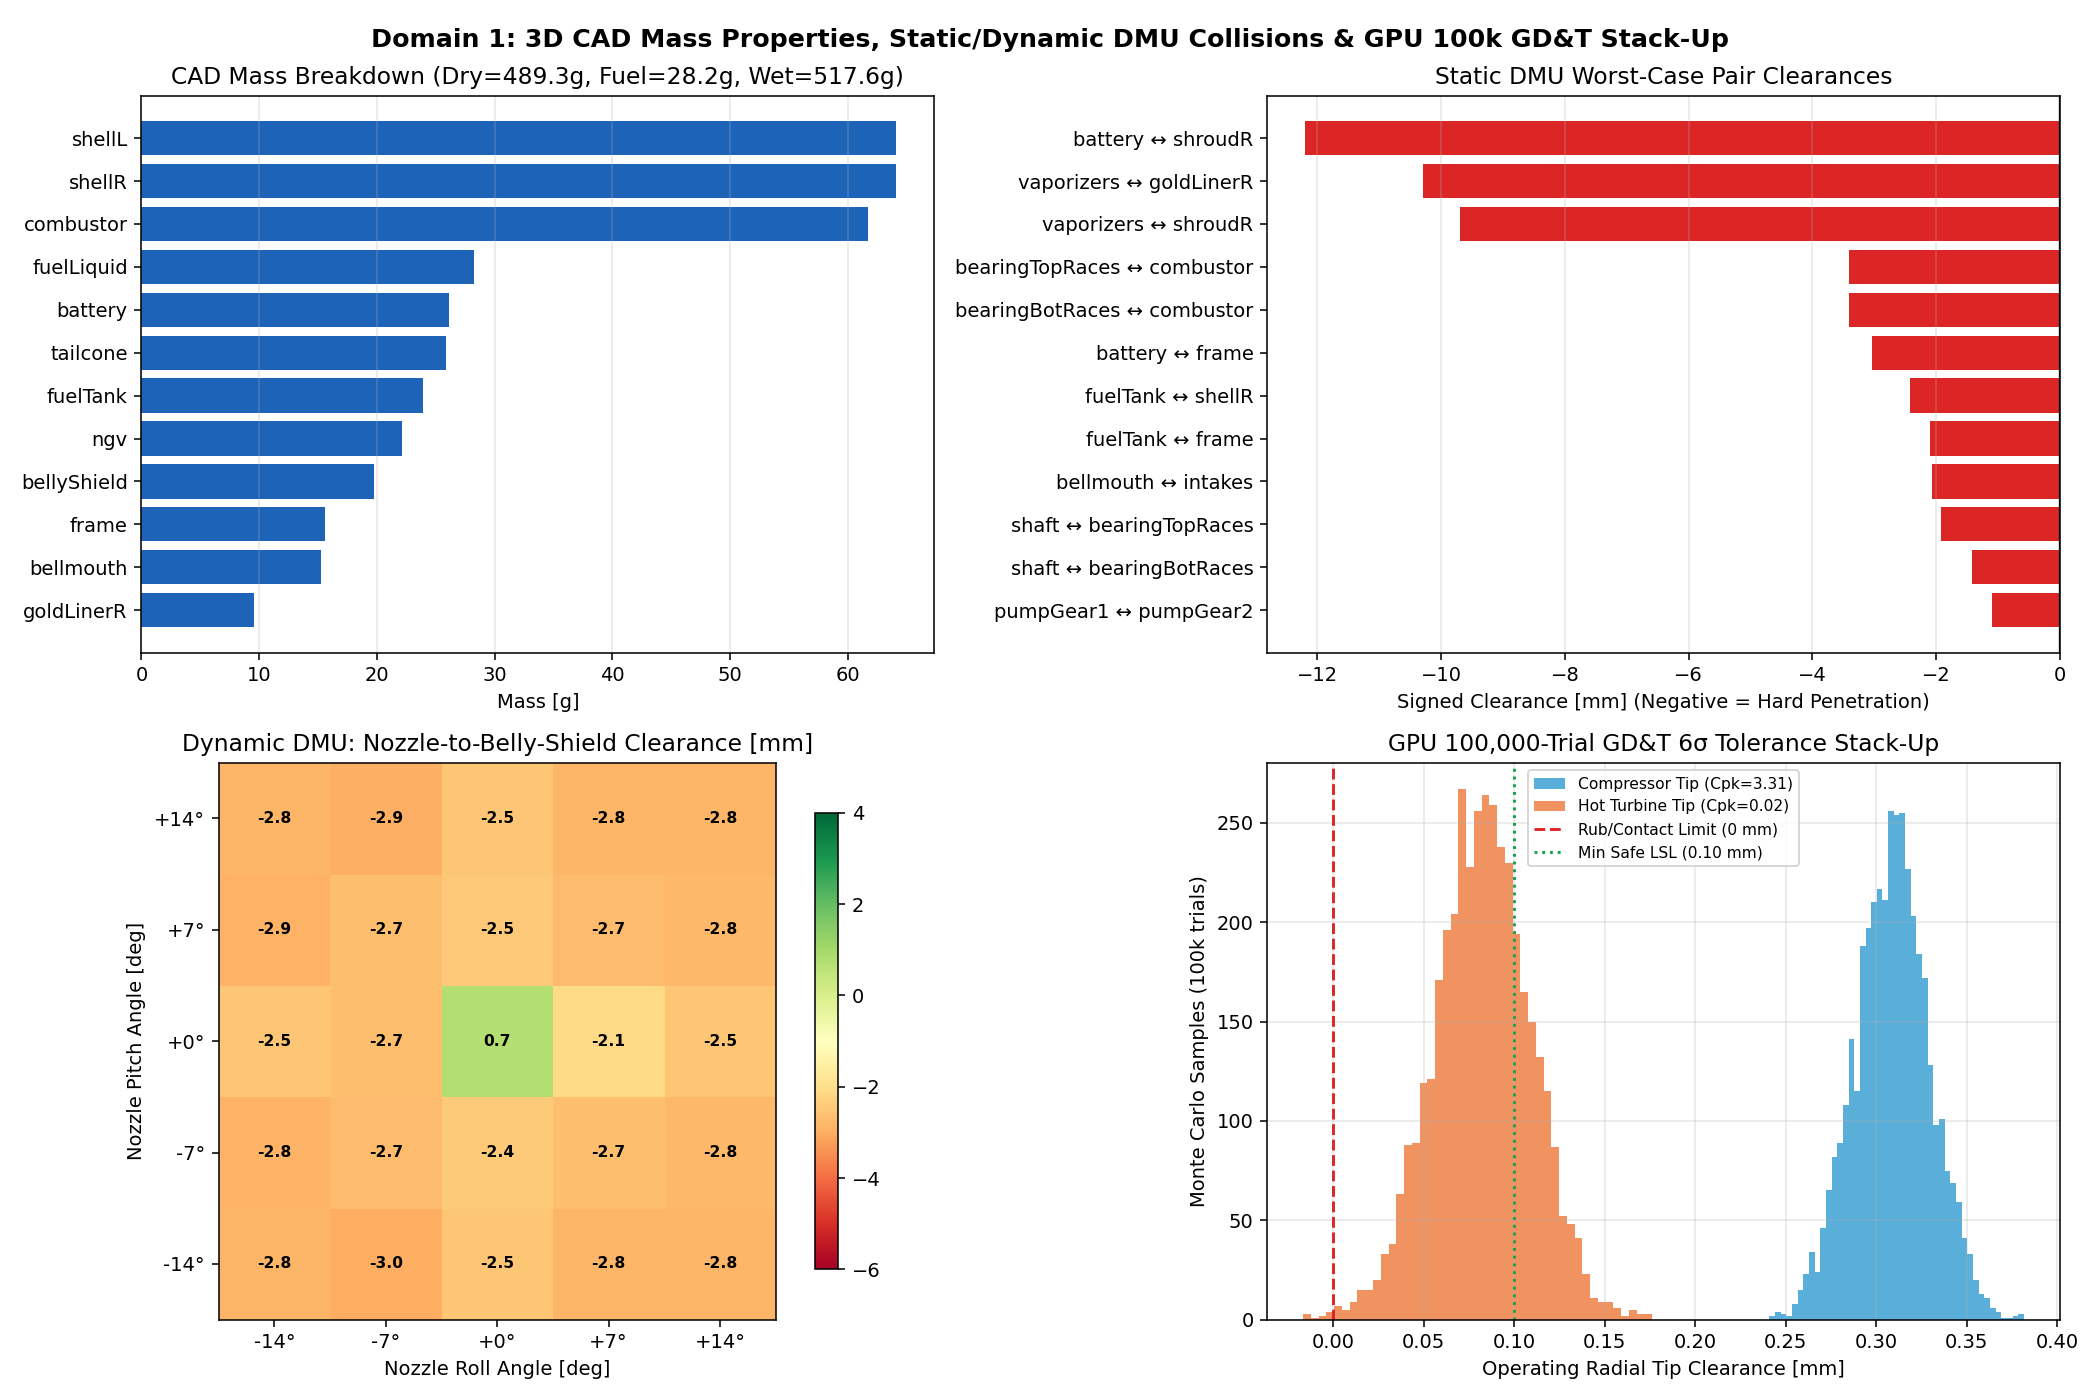
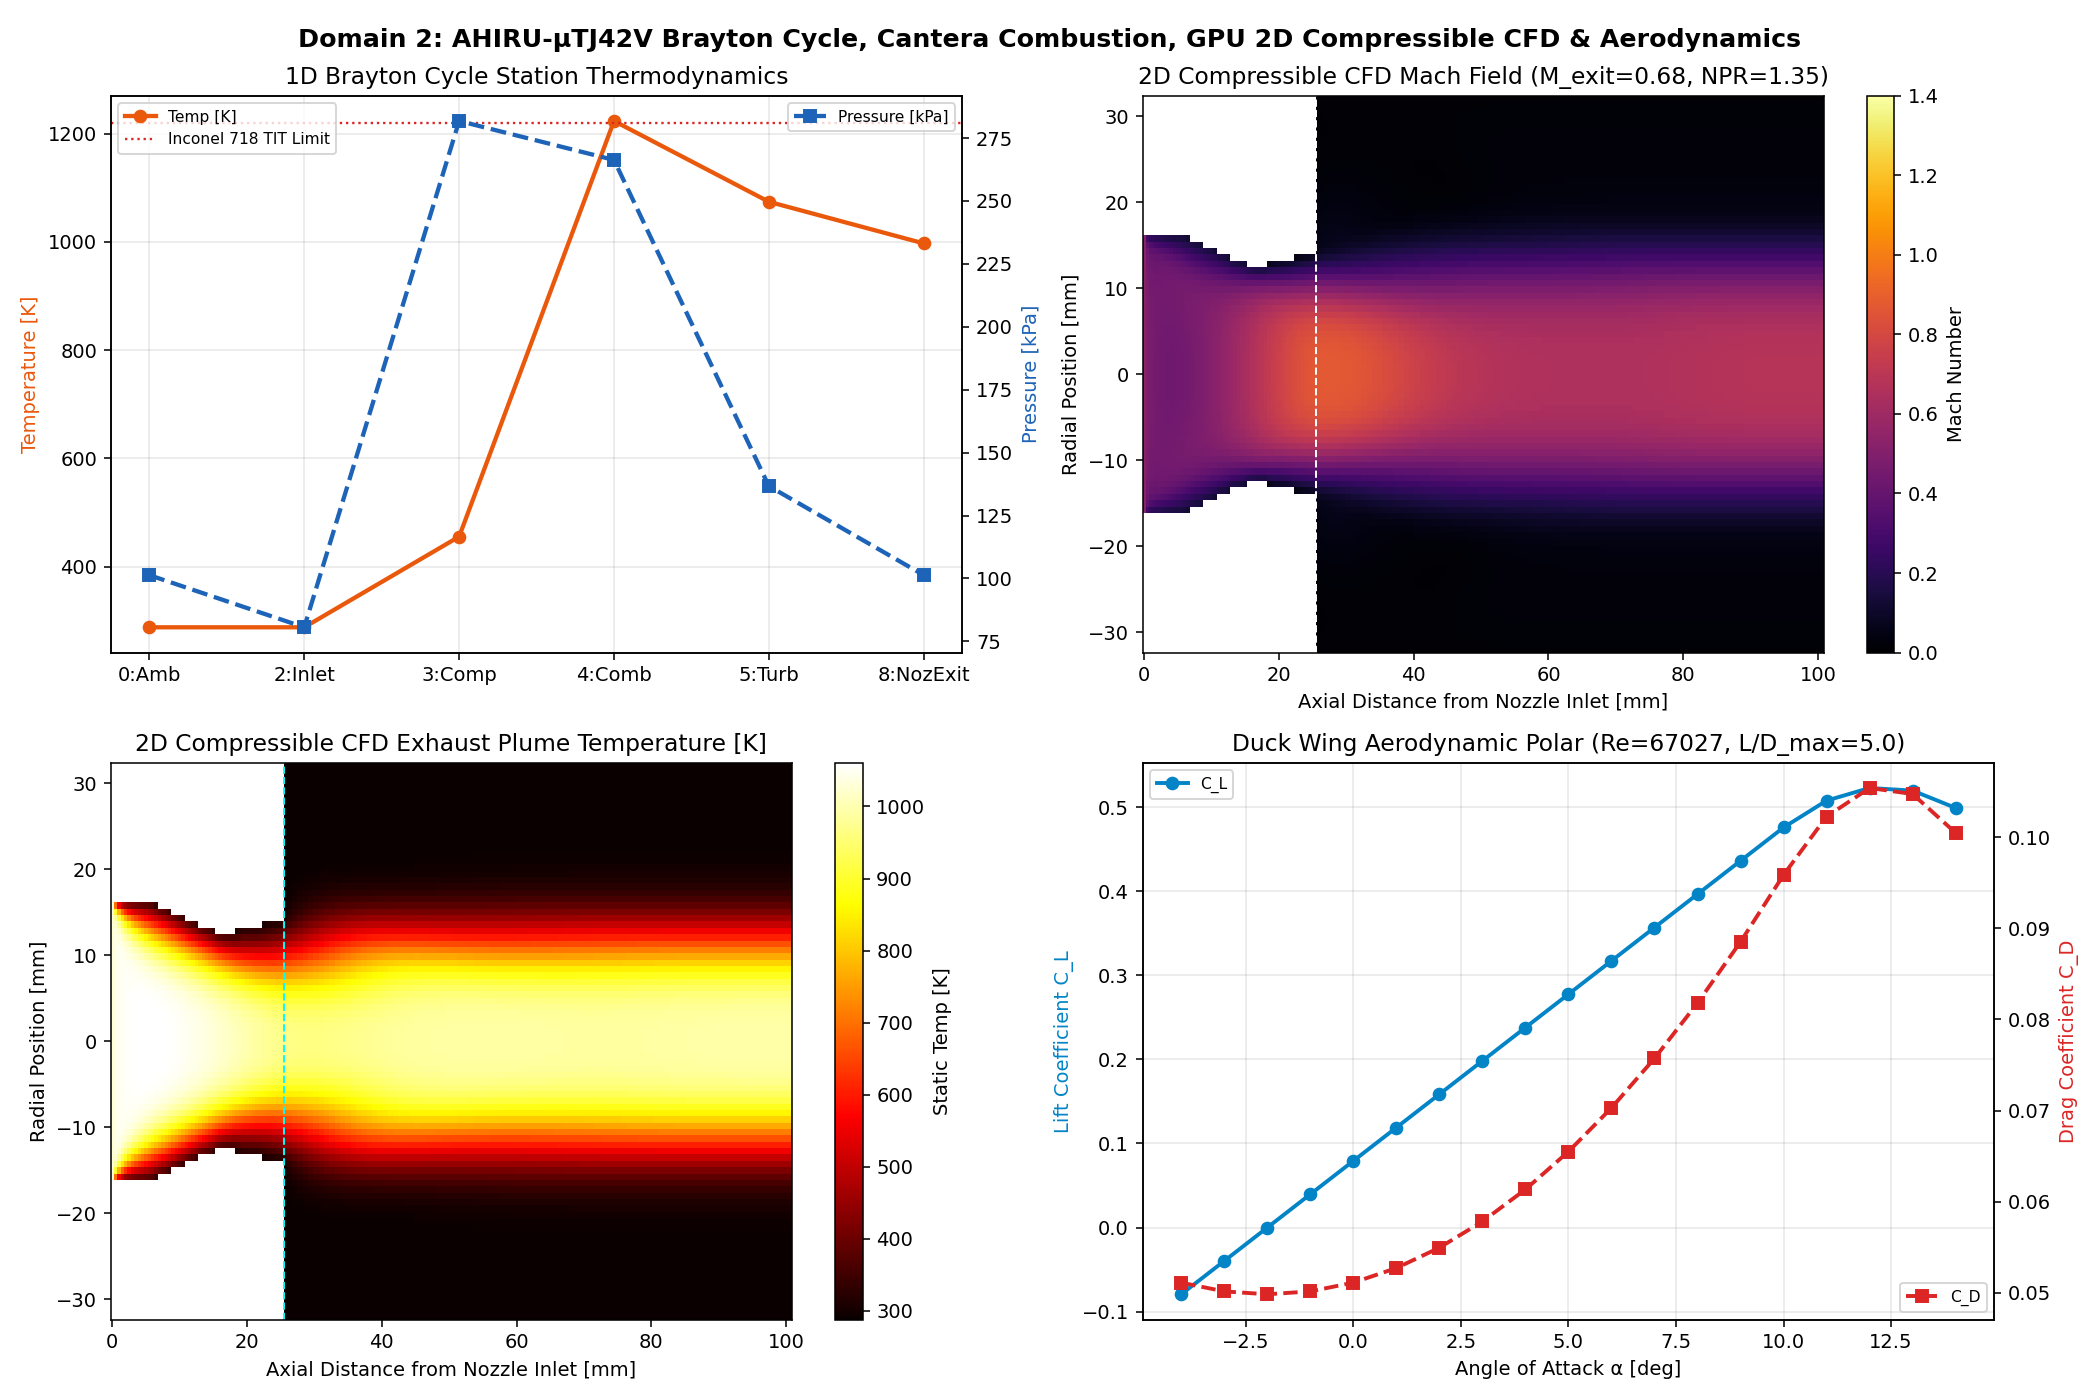
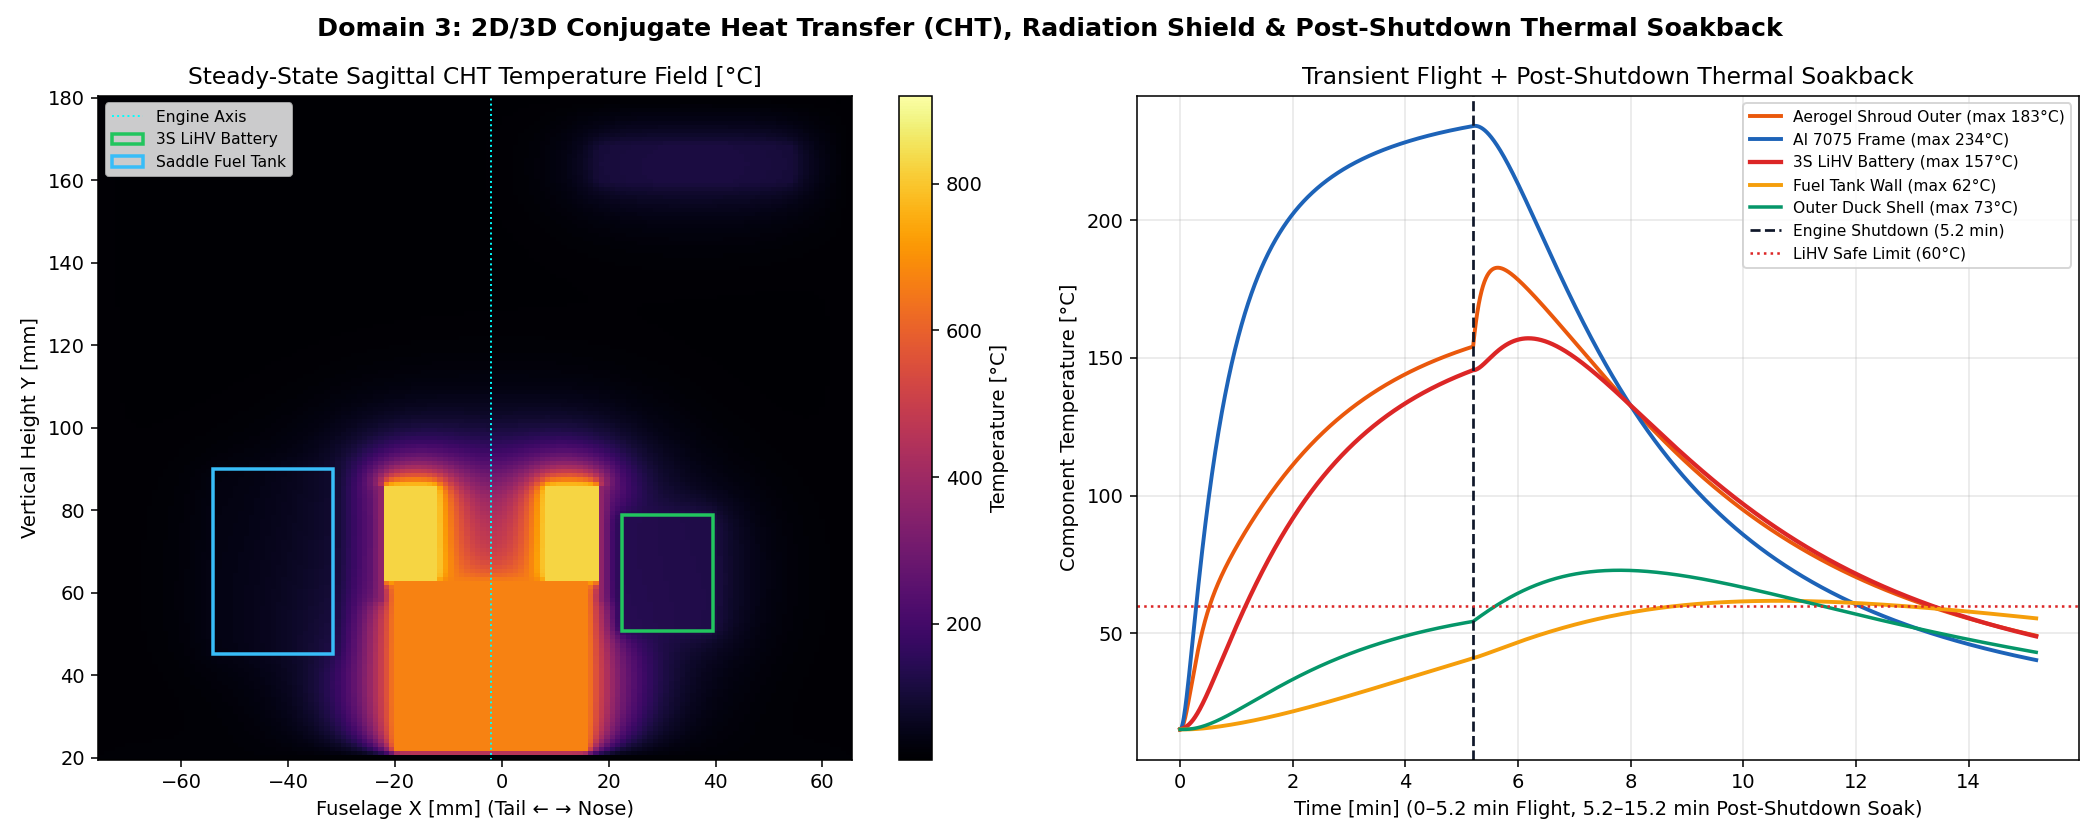
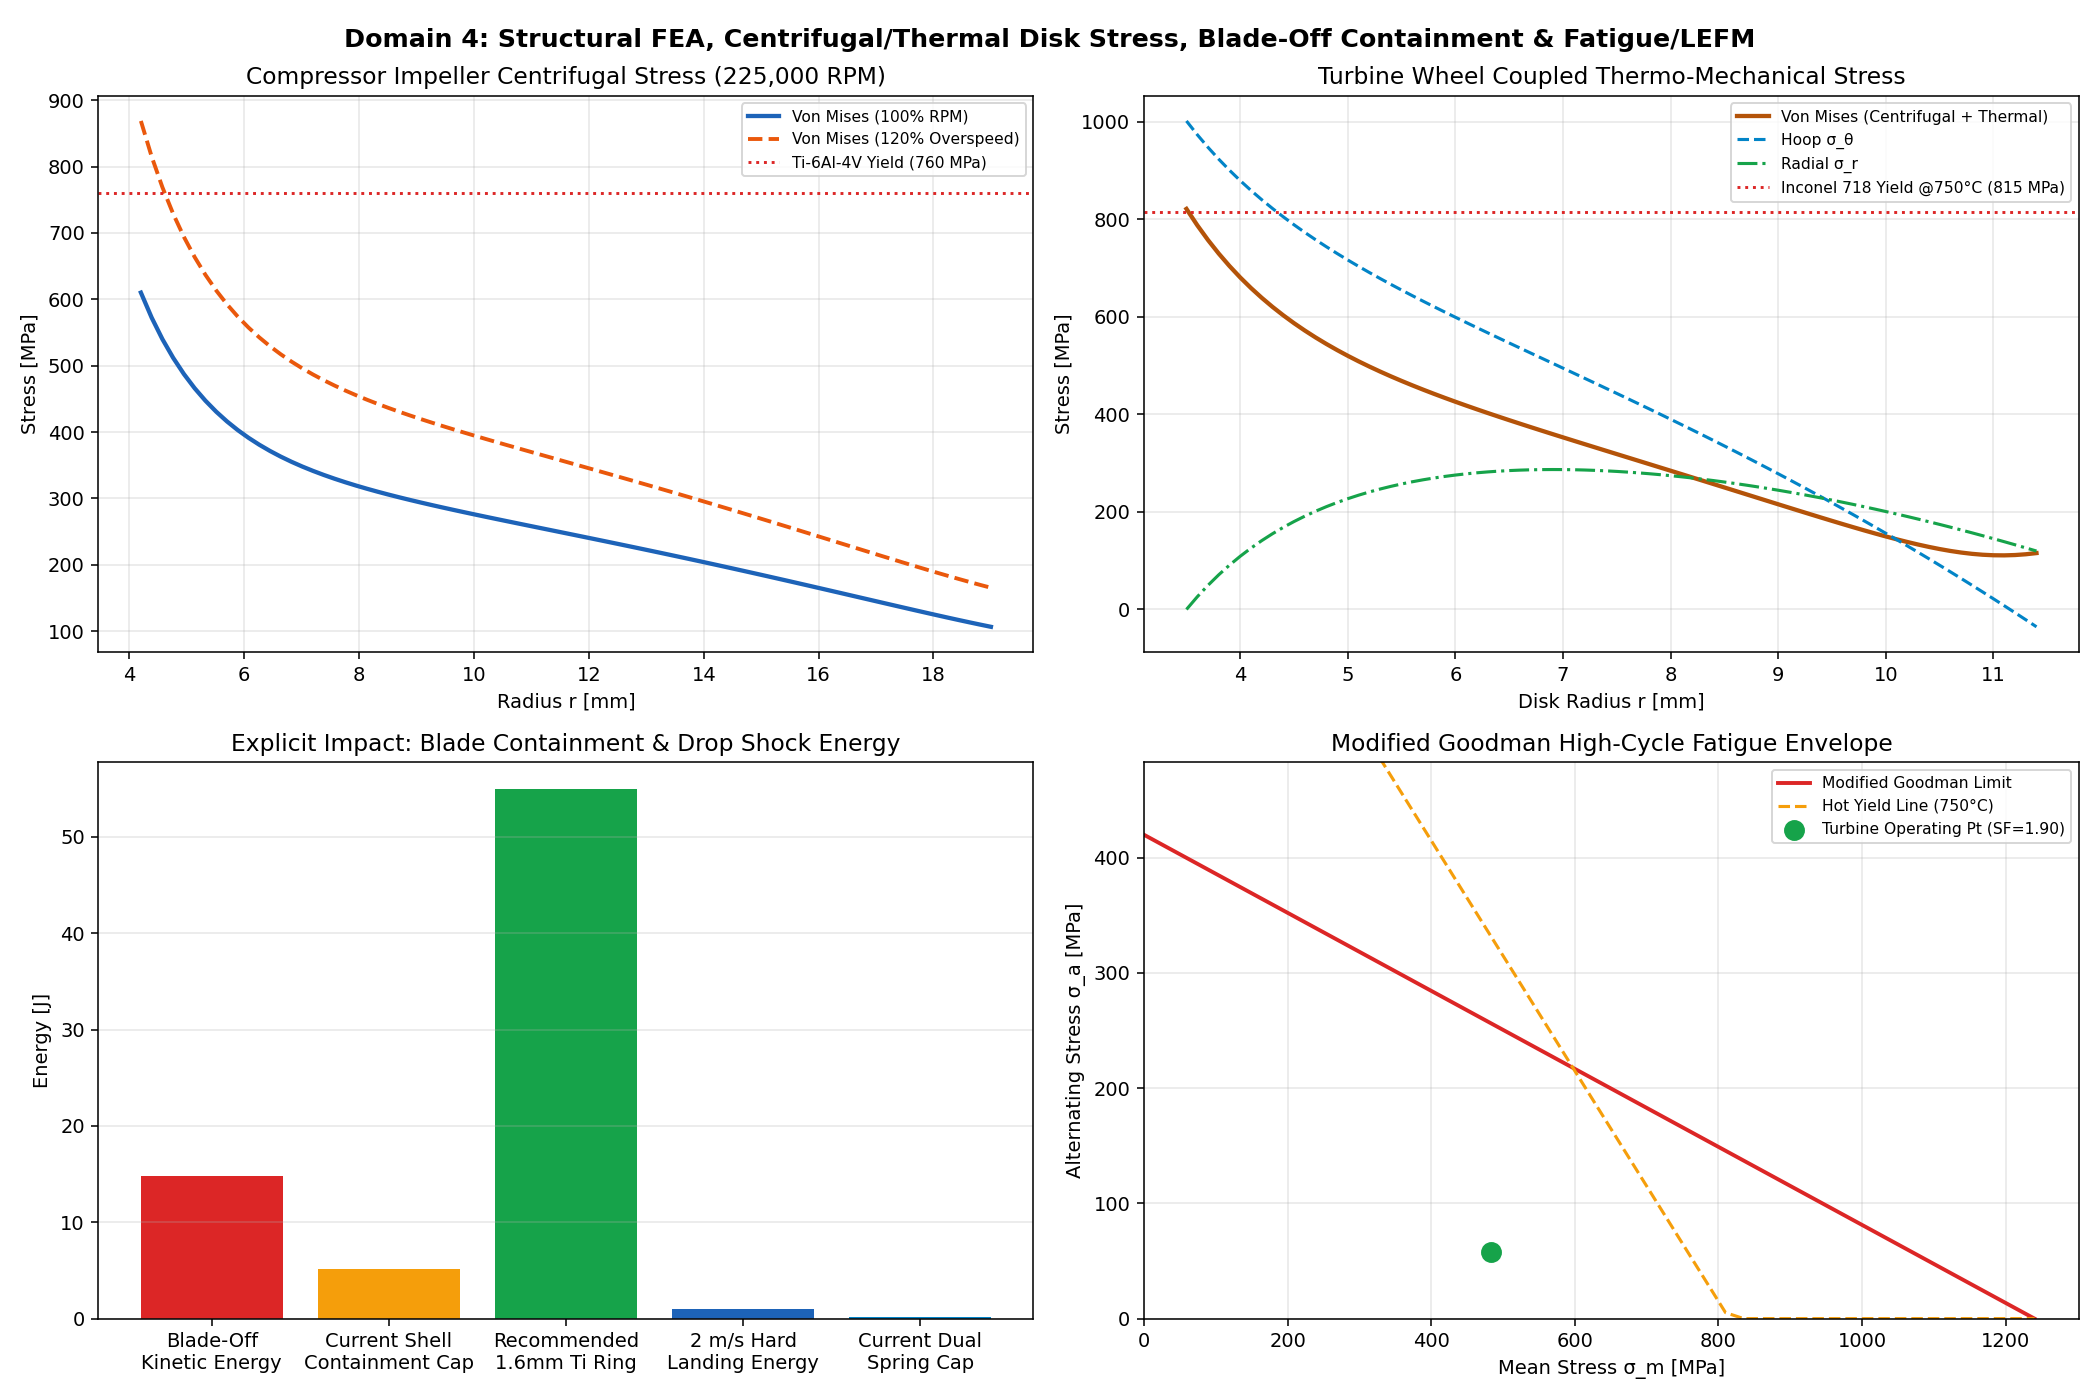
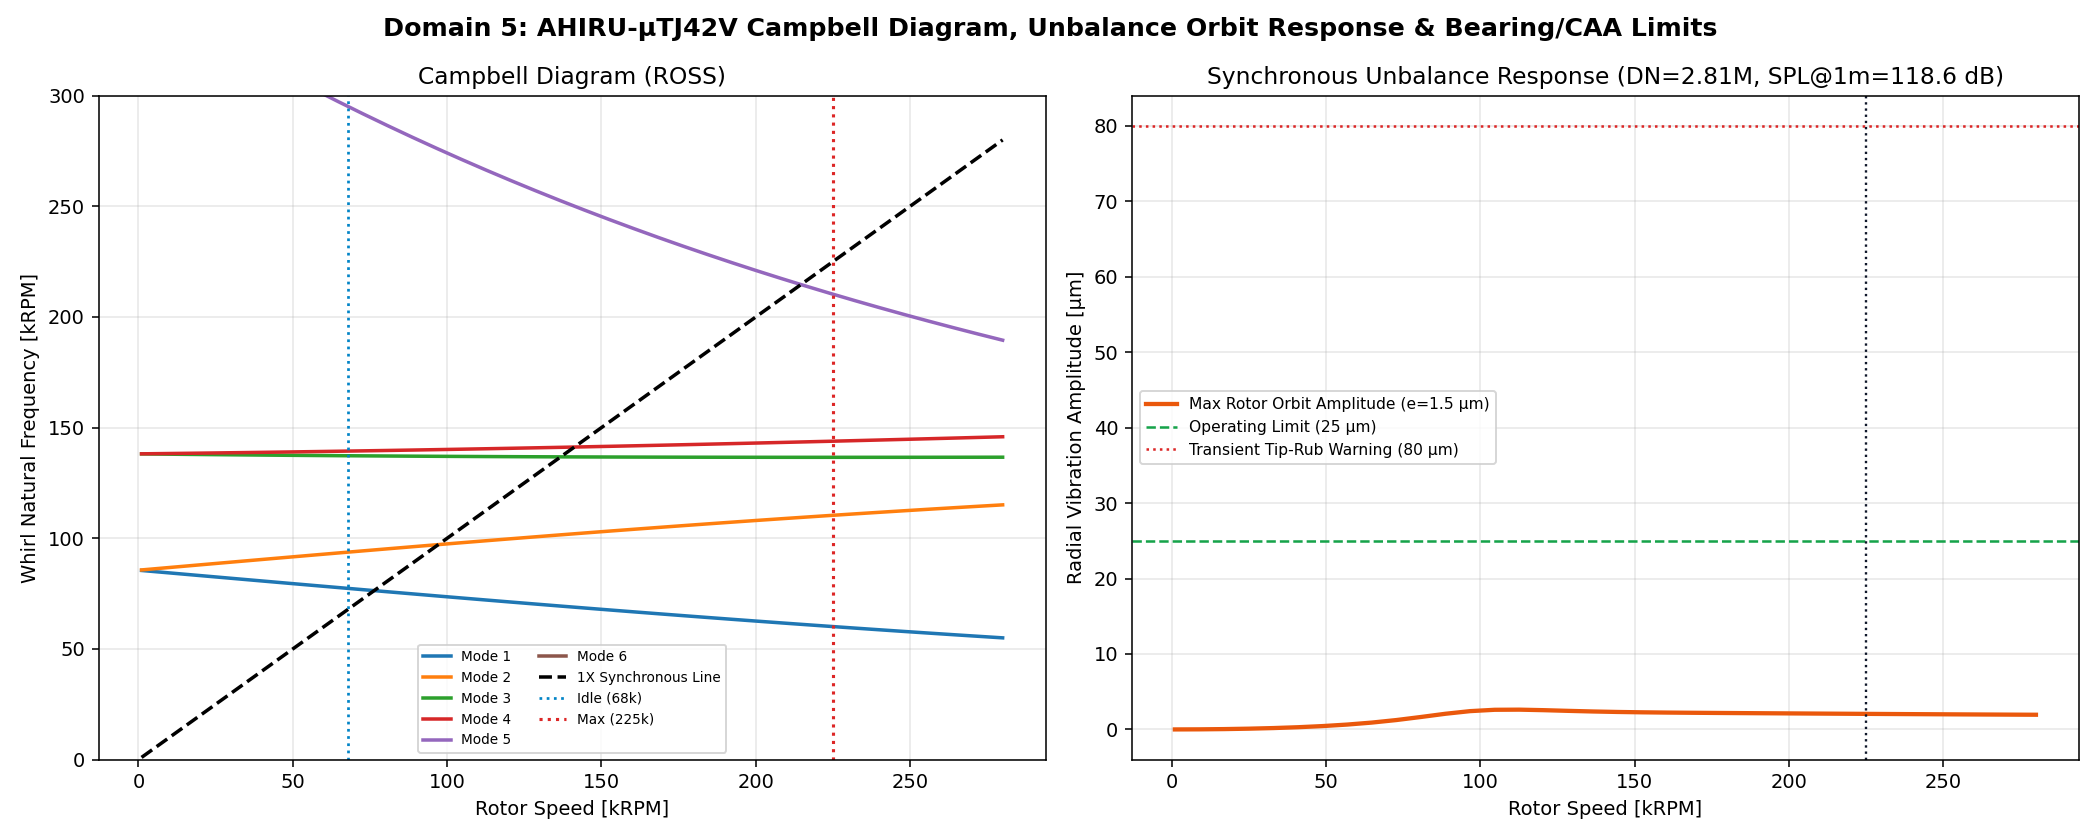
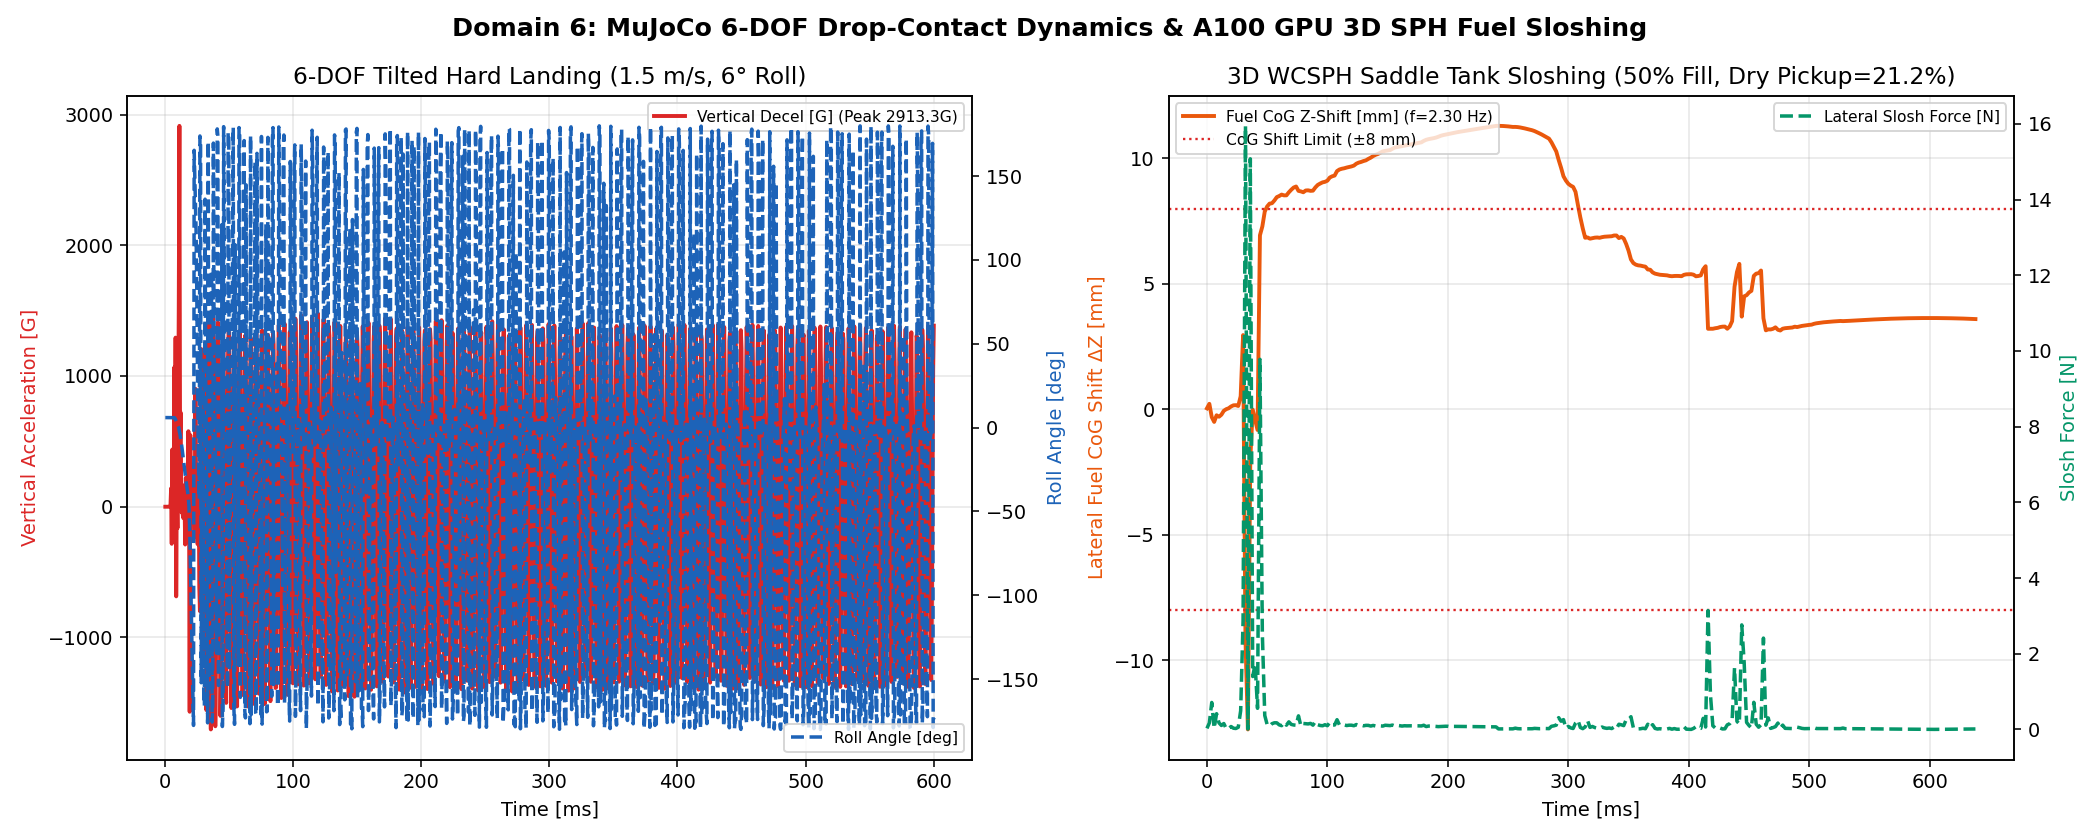
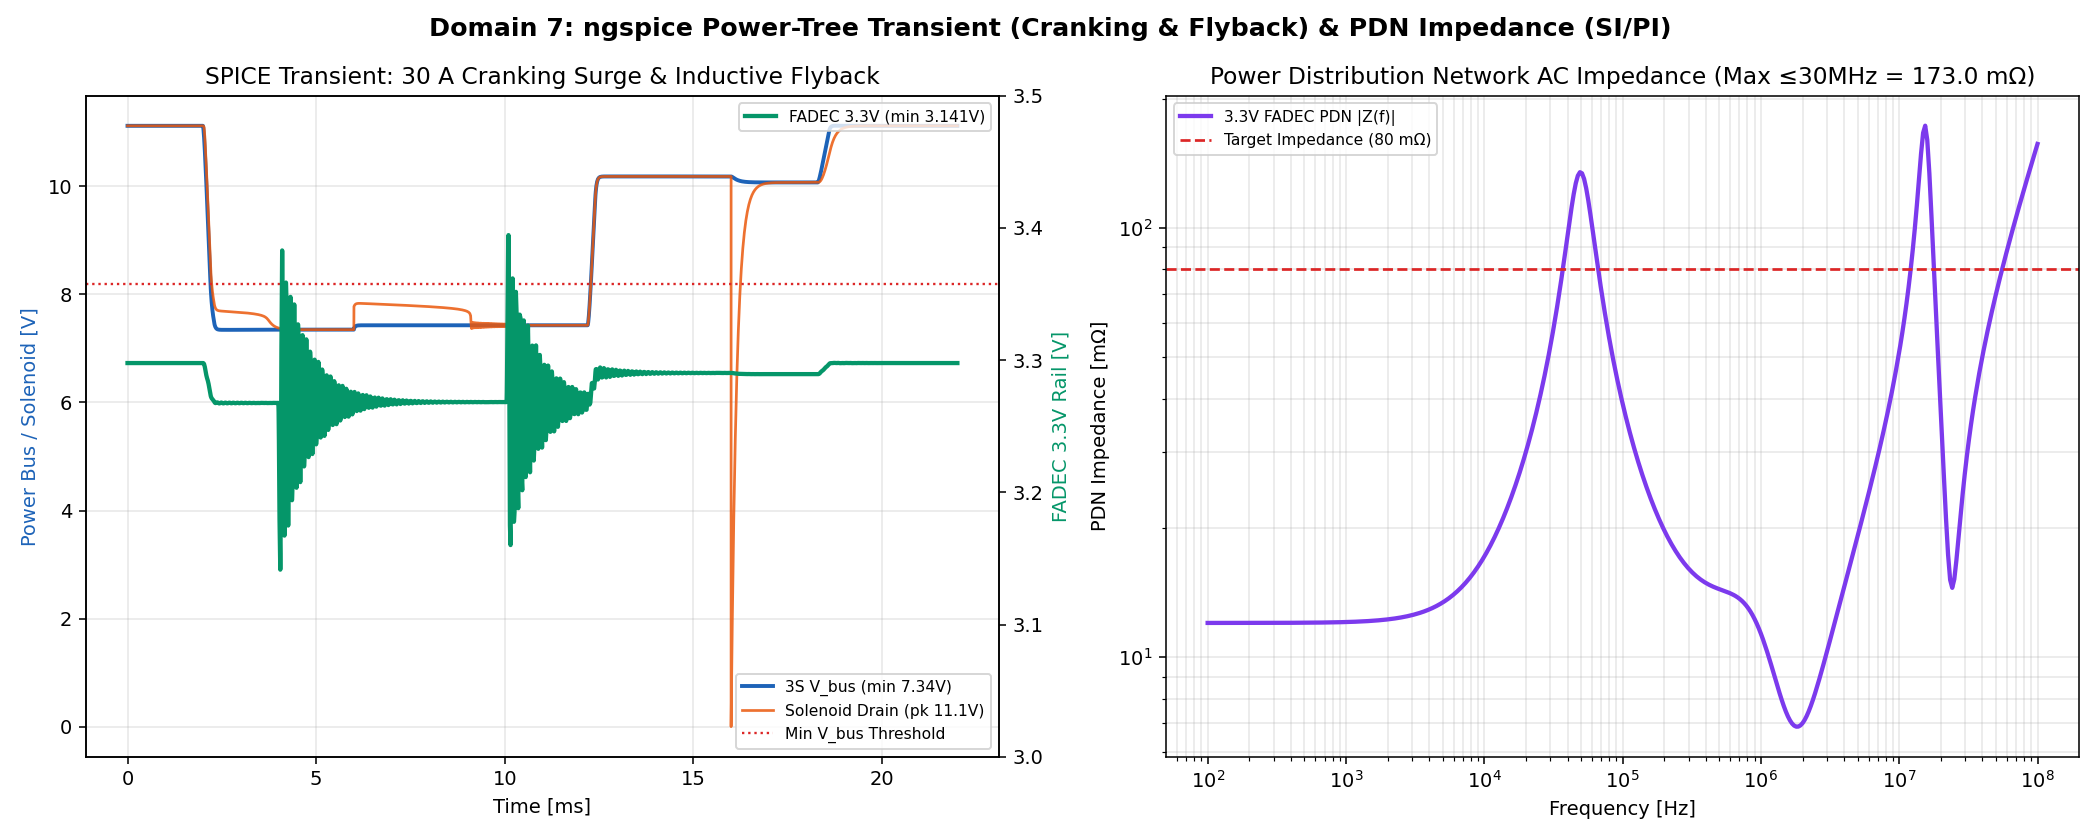
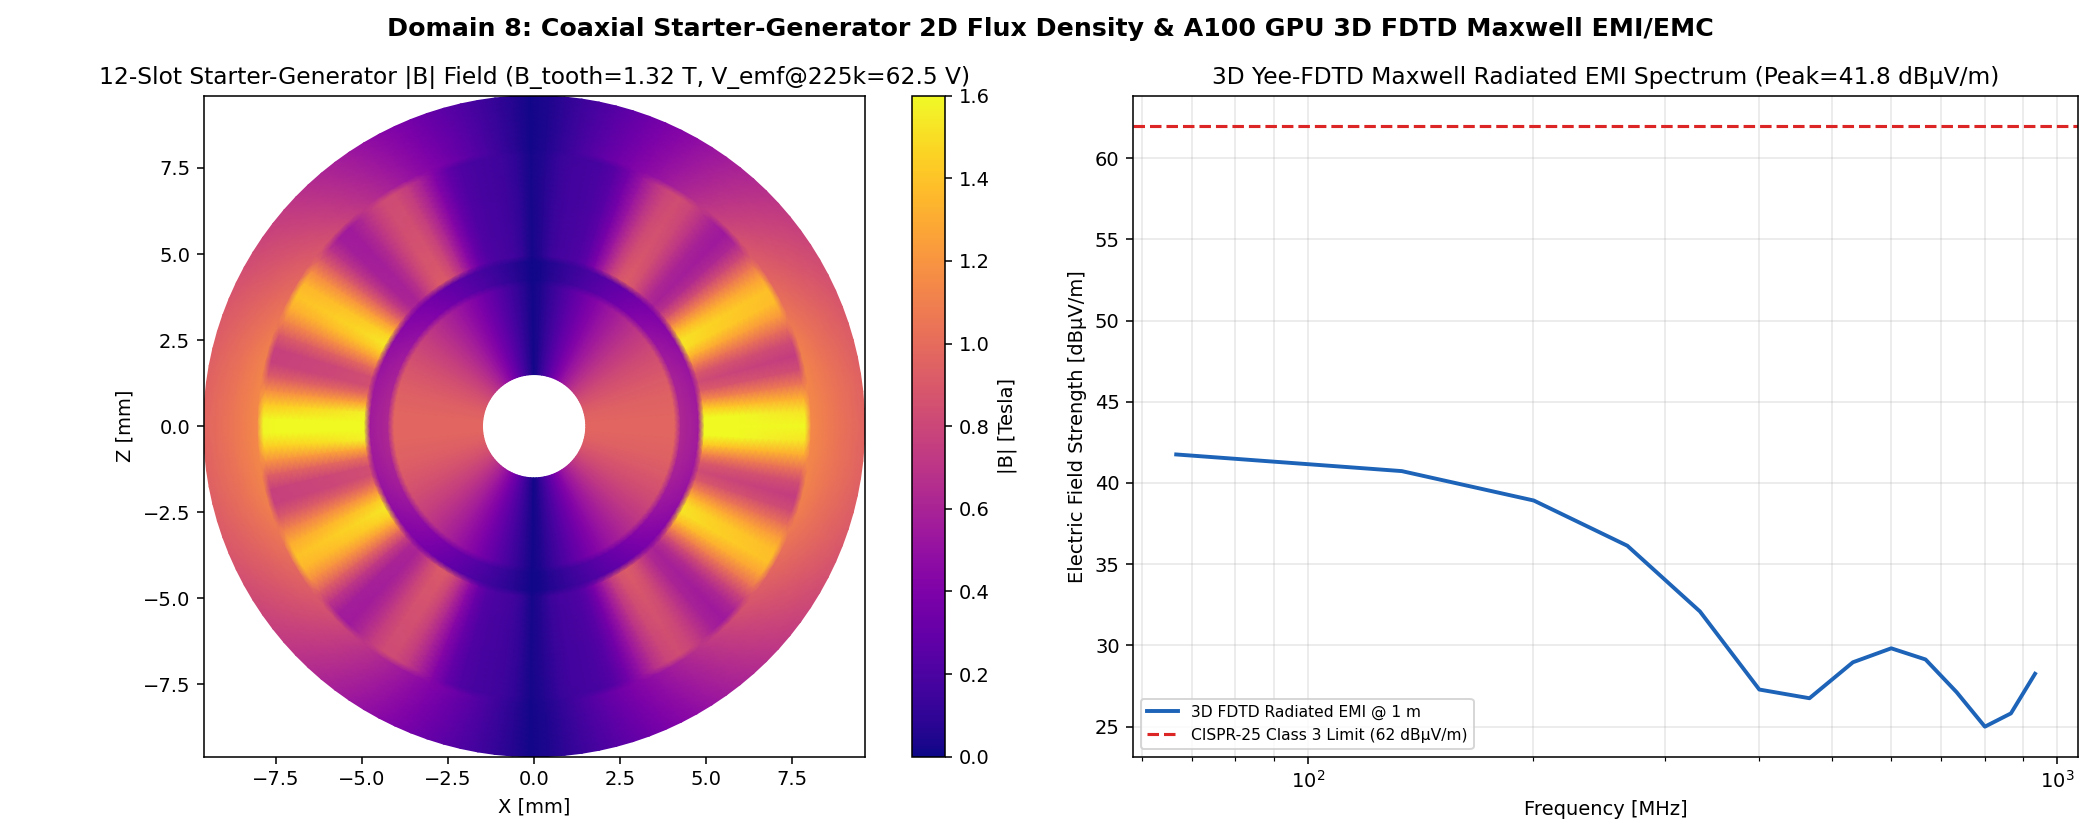
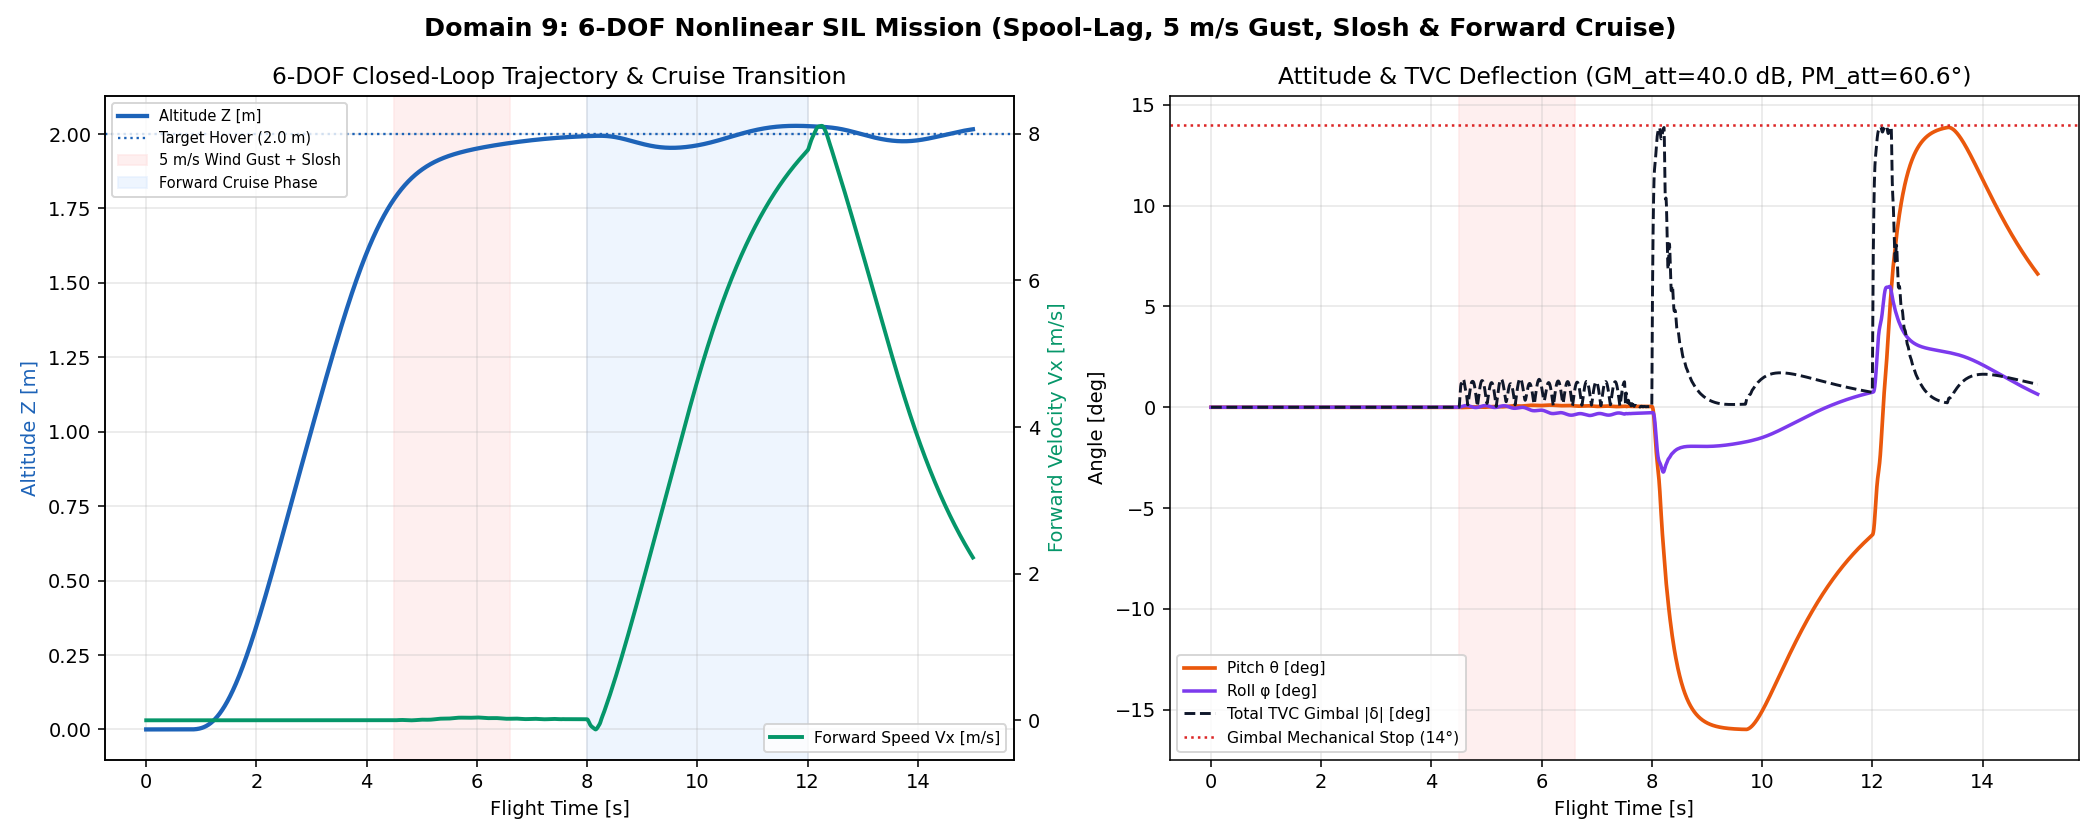
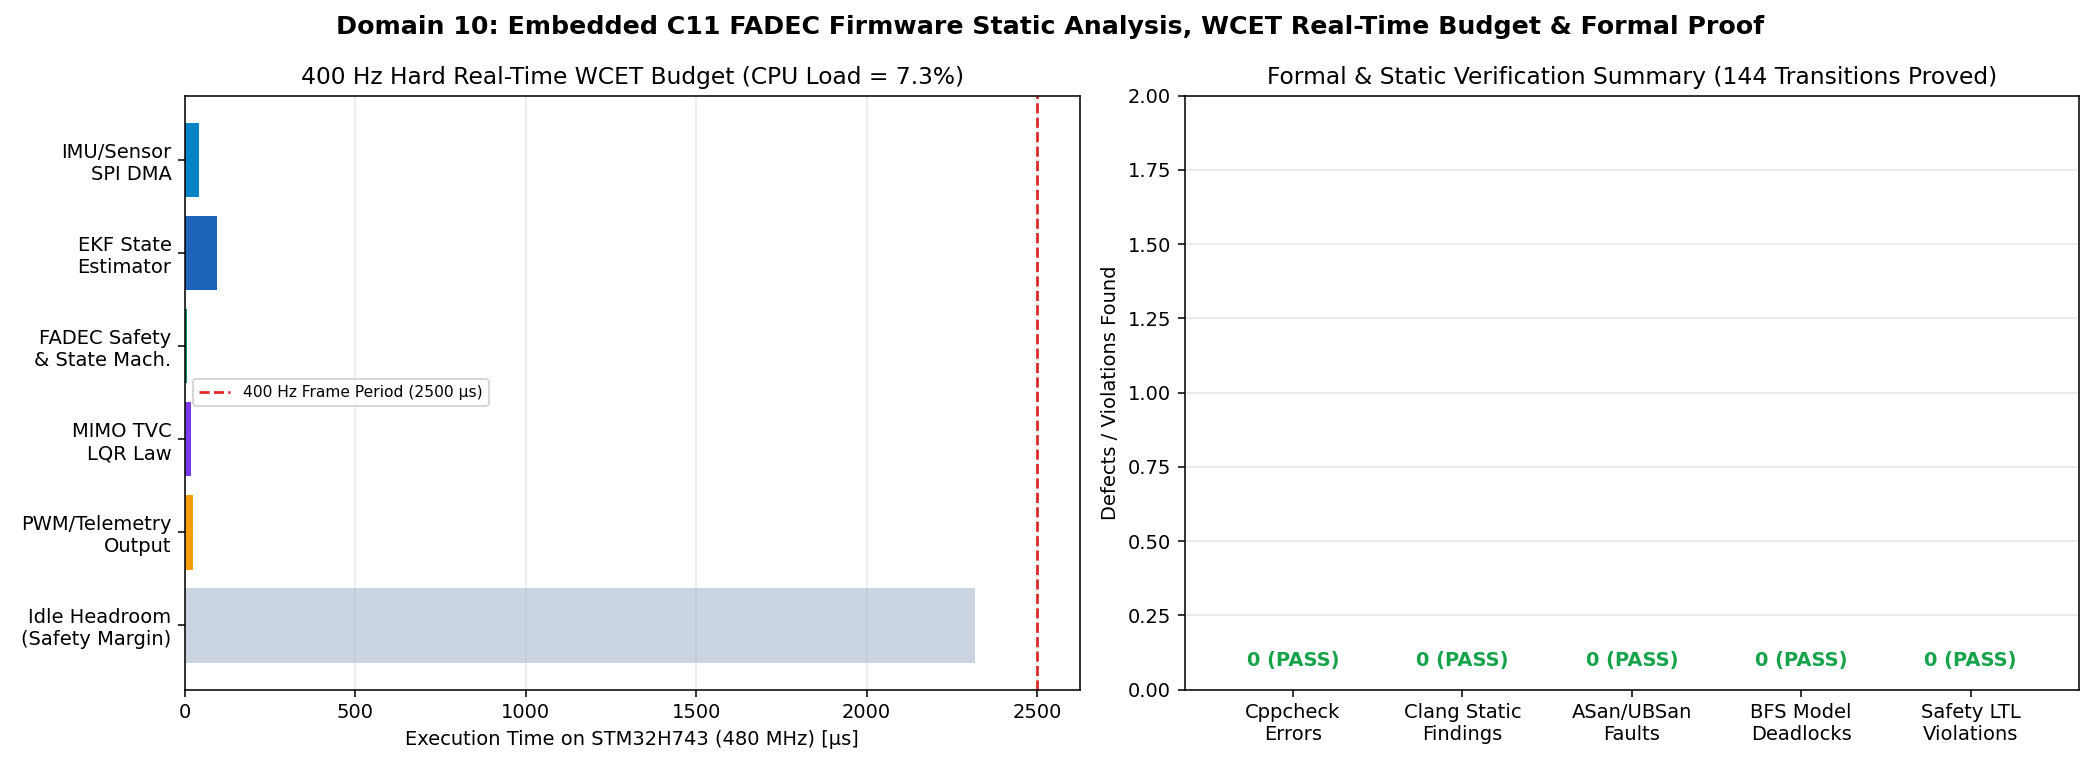
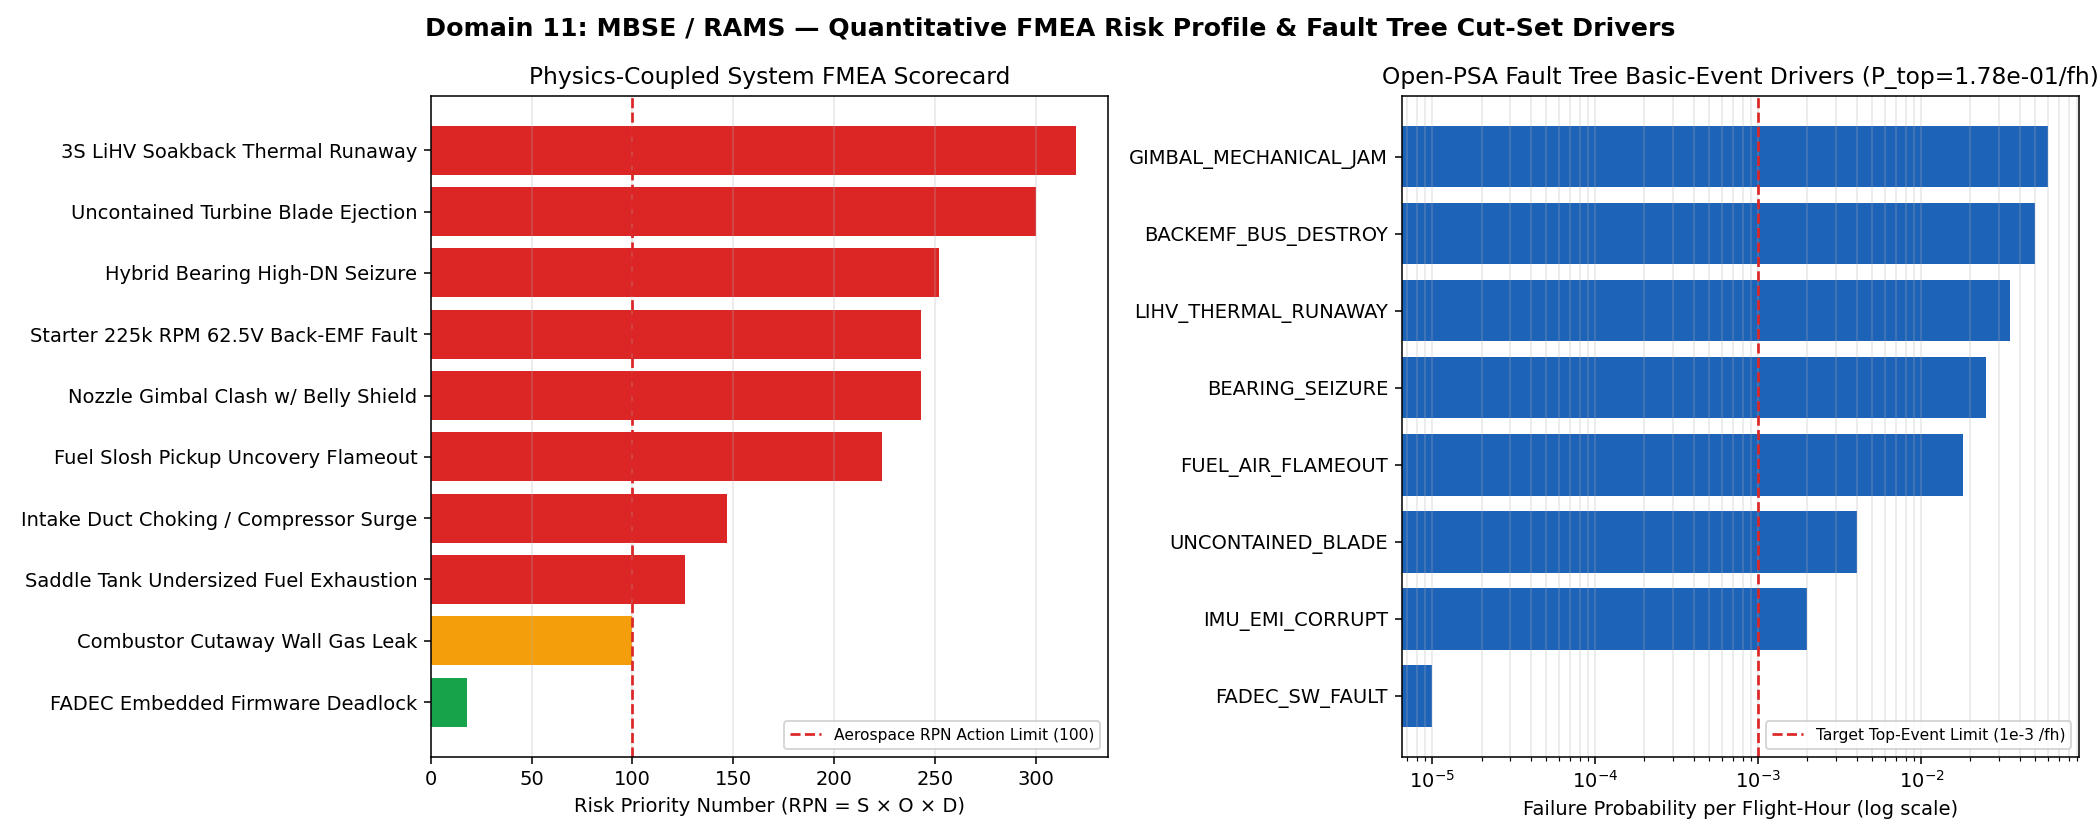
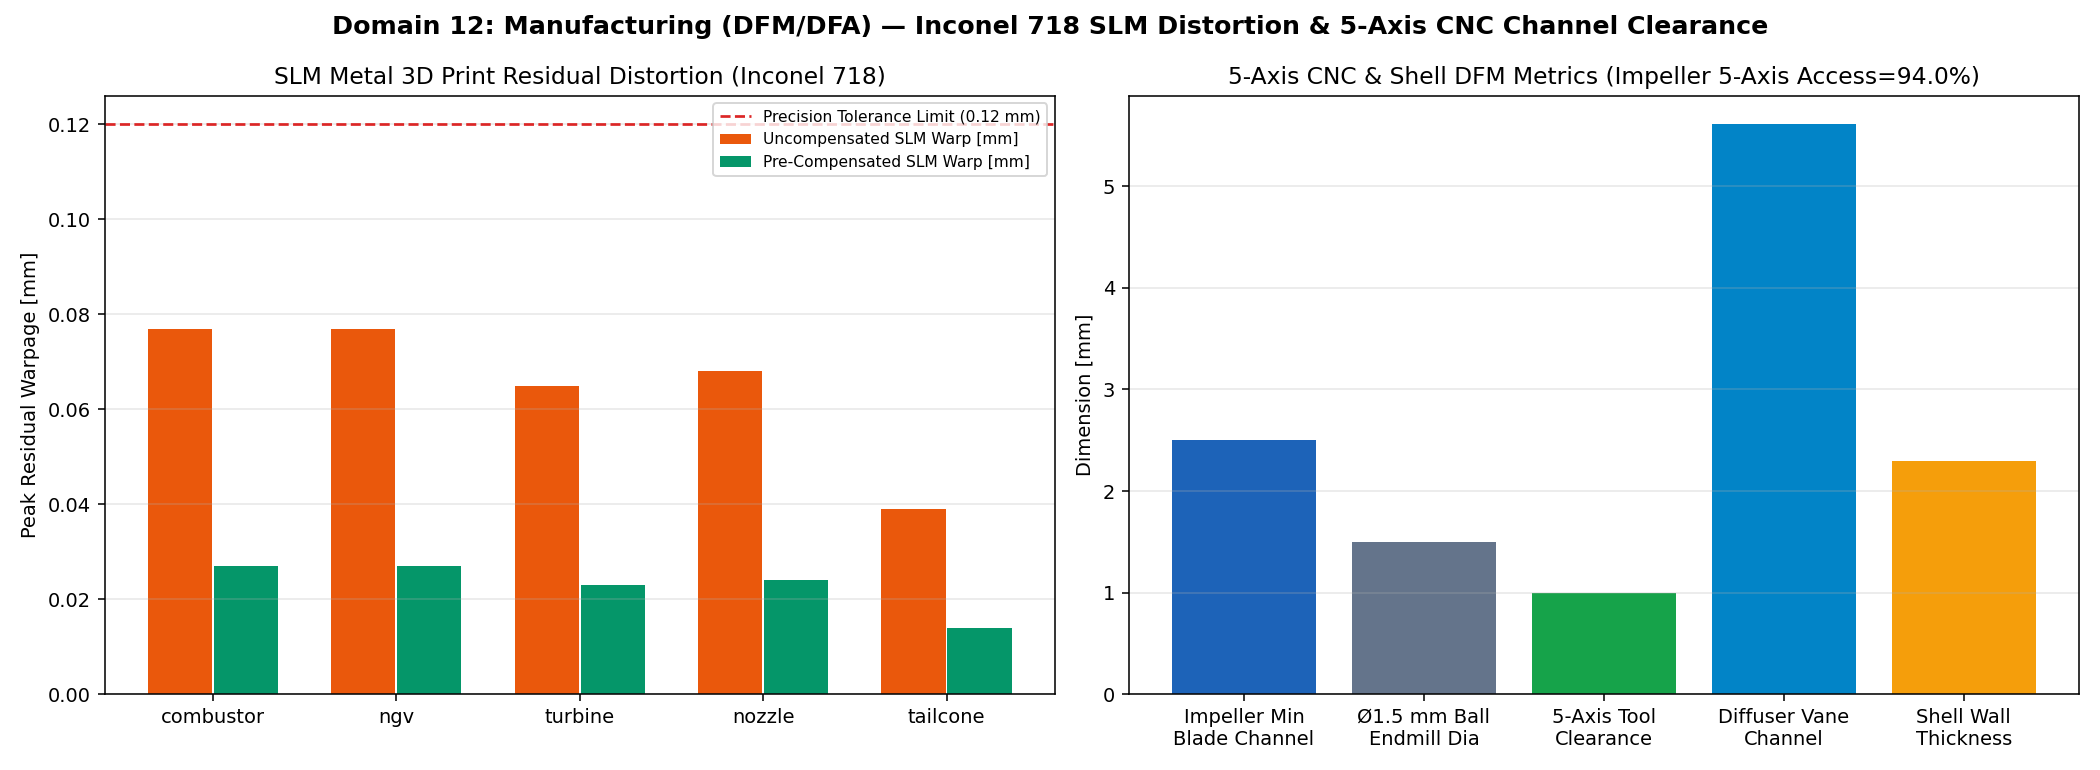

In [4]:
#@title 4. エグゼクティブ検証ダッシュボード & 全12領域エンジニアリング解析図の表示
from IPython.display import HTML, Image, display
import json

print("=== [4/5] Executive Scorecard Summary ===")
data = json.loads(outputs["json"].read_text(encoding="utf-8"))
s = data["summary"]
print(f"Overall Verdict : {data['overall_verdict']}")
print(f"Checks Summary  : {s['checks_pass']} PASS | {s['checks_marginal']} MARGINAL | {s['checks_fail']} FAIL (Total {s['checks_total']} checks, {s['pass_rate_pct']}%)")
print(f"Domains 100% OK : {s['domains_fully_passed']} / {s['domains_total']}")
print("\n--- Domain-by-Domain Breakdown ---")
for d in data["domains"]:
    print(f"  Domain {d['domain_id']:02d} [{d['overall_verdict']:8s}] {d['title_ja']} ({d['pass_count']}P / {d['marginal_count']}M / {d['fail_count']}F, {d['elapsed_sec']:.2f}s)")

# Render complete self-contained HTML verification dashboard directly in Colab!
display(HTML(outputs["html"].read_text(encoding="utf-8")))


In [5]:
#@title 5. 全検証レポート + 商用CAE互換デッキ一式（ZIP）のワンクリックダウンロード
import os
from pathlib import Path

zip_path = outputs["zip"]
size_mb = zip_path.stat().st_size / (1024 ** 2)
print(f"=== [5/5] Verification Archive Ready: {zip_path} ({size_mb:.2f} MB) ===")
print("\nIncluded Commercial CAE Interchange Decks & Reports:")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file() and p.suffix in (".html", ".json", ".md", ".step", ".scad", ".inp", ".cfg", ".xml", ".cir", ".kicad_pcb", ".lua", ".c", ".h", ".pml"):
        print(f"  - {p.relative_to(OUT_DIR)}")

if AUTO_DOWNLOAD_ZIP:
    try:
        from google.colab import files
        files.download(str(zip_path))
    except ImportError:
        print("(Not running inside Google Colab UI — archive saved locally at:", zip_path, ")")


=== [5/5] Verification Archive Ready: /content/ahiru_v12_out/ahiru_v12_verification_bundle.zip (8.13 MB) ===

Included Commercial CAE Interchange Decks & Reports:
  - ahiru_nozzle_su2.cfg
  - ahiru_thermal_cht.inp
  - ahiru_v12_dashboard.html
  - ahiru_v12_report.json
  - ahiru_v12_summary.md
  - cad/ahiru_assembly.scad
  - cad/ahiru_parametric_core.step
  - cad/assembly_manifest.json
  - dfm_cam/ahiru_dfm_cam_spec.json
  - eda/ahiru_fadec.kicad_pcb
  - eda/ahiru_power_tree.cir
  - em_emc/ahiru_starter_femm.lua
  - fea_calculix/ahiru_turbine_disk.inp
  - firmware/ahiru_fadec.c
  - firmware/ahiru_fadec.h
  - firmware/ahiru_fadec.pml
  - firmware/ahiru_fadec_test.c
  - firmware/pan.c
  - firmware/pan.h
  - gnc/ahiru_jsbsim.xml
  - mbd_ahiru.xml
  - rams/ahiru_fta.xml
  - rams/sysml_rtm_icd.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>